# Практические работы 1-7 по R
**Студент:** Токарев  
**Репозиторий:** [OXOTAHAAPTEMACOBA2210/Pz_Tokarev](https://github.com/OXOTAHAAPTEMACOBA2210/Pz_Tokarev)

Этот блокнот полностью настроен для запуска в **Google Colab** (ядро R).
Нажимайте кнопку Play последовательно по ячейкам.


## 0. Скачивание файлов данных и установка пакетов


In [1]:
# 1. Скачиваем репозиторий с датасетами (bmw.csv, Employee.csv) и скриптами
if (!file.exists("bmw.csv")) {
  system("git clone https://github.com/OXOTAHAAPTEMACOBA2210/Pz_Tokarev.git temp_repo")
  file.copy(list.files("temp_repo", full.names = TRUE), ".", recursive = TRUE)
  unlink("temp_repo", recursive = TRUE)
}
list.files()


[1] "bmw.csv"                        "CHEAT_SHEET.md"                
 [3] "Employee.csv"                   "evals.csv"                     
 [5] "plots"                          "Pz_Tokarev_Colab.ipynb"        
 [7] "README.md"                      "Rplots.pdf"                    
 [9] "sample_data"                    "task1_basics.R"                
[11] "task2_dataframes.R"             "task3_descriptive_stats.R"     
[13] "task4_correlation_regression.R" "task5_multiple_regression.R"   
[15] "task6_logistic_regression.R"    "task7_machine_learning.R"

In [2]:
# 2. Установка необходимых библиотек для графики, статистики и ML
pkgs <- c("ggplot2", "psych", "ROCR", "caTools", "party", "randomForest", "e1071")
new_pkgs <- pkgs[!(pkgs %in% installed.packages()[, "Package"])]
if (length(new_pkgs)) install.packages(new_pkgs, repos = "https://cloud.r-project.org")
cat("Библиотеки готовы к работе!\n")


Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘TH.data’, ‘gtools’, ‘libcoin’, ‘matrixStats’, ‘multcomp’, ‘mnormt’, ‘GPArotation’, ‘gplots’, ‘bitops’, ‘mvtnorm’, ‘modeltools’, ‘strucchange’, ‘coin’, ‘zoo’, ‘sandwich’, ‘proxy’




Библиотеки готовы к работе!


## ПЗ 1. Основы работы с R


In [3]:
# Занятие 1. Основы работы с R

# 1. Поголовье животных
cattle <- 3456
pig_population <- 7333
chicken_population <- 23459

meat_cows <- 1320
milk_cows <- cattle - meat_cows
milk_cows

egg_chickens <- 12457
meat_chickens <- chicken_population - egg_chickens
meat_chickens

# 2. Перевозка свиней
total_pigs <- 1457
capacity <- 14

trucks <- total_pigs %/% capacity
trucks

remaining_pigs <- total_pigs %% capacity
remaining_pigs

# 3. Тестовые коровы и надой
milk_per_day <- c(12, 4, 7, 18, 10)
annual_milk <- milk_per_day * 365
annual_milk

mean_annual <- mean(annual_milk)
mean_annual
# средний надой 3723 литра, это меньше 5000-7000 л, коровы не высокопродуктивные

# 4. Датафрейм с коровами
cows_names <- c("Ералаш", "Пальто", "Кощей", "Адидас", "Зима")
cows_df <- data.frame(
  Name = cows_names,
  Daily_Yield = milk_per_day,
  Annual_Yield = annual_milk
)
cows_df


[1] 2136

[1] 11002

[1] 104

[1] 1

[1] 4380 1460 2555 6570 3650

[1] 3723

Name,Daily_Yield,Annual_Yield
<chr>,<dbl>,<dbl>
Ералаш,12,4380
Пальто,4,1460
Кощей,7,2555
Адидас,18,6570
Зима,10,3650


## ПЗ 2. Работа с датафреймами (Employee.csv)


In [4]:
# Занятие 2. Работа с Дата фреймами (Employee.csv)

# 1. Загрузка данных и структура
df <- read.csv("Employee.csv", stringsAsFactors = FALSE)
nrow(df)
ncol(df)
str(df)

# уникальные значения качественных признаков
unique(df$Education)
unique(df$City)
unique(df$Gender)
unique(df$EverBenched)

# 2. summary для данных
summary(df)

# 3. Сотрудники старше и младше среднего возраста
mean_age <- mean(df$Age)
mean_age
older <- df[df$Age > mean_age, ]
younger <- df[df$Age < mean_age, ]
head(older)
head(younger)

# 4. Присоединились до 2016 года (пол, возраст, стаж)
early_emp <- df[df$JoiningYear < 2016, c("Gender", "Age", "ExperienceInCurrentDomain")]
head(early_emp)

# 5. Средний уровень оплаты и возраст уволившихся
mean(df$PaymentTier[df$LeaveOrNot == 1])
mean(df$Age[df$LeaveOrNot == 1])

# 6. Мин и макс стаж для PaymentTier == 3
min(df$ExperienceInCurrentDomain[df$PaymentTier == 3])
max(df$ExperienceInCurrentDomain[df$PaymentTier == 3])
range(df$ExperienceInCurrentDomain[df$PaymentTier == 3])

# 7. Увольнения среди мужчин и женщин
table(df$Gender, df$LeaveOrNot)
prop.table(table(df$Gender, df$LeaveOrNot), 1)

# 8. Различия в уровне оплаты
table(df$Gender, df$PaymentTier)

# 9. Город регистрации большинства
table(df$City)

# 10. Средний возраст тех, кто раньше всех пришел в компанию
min_year <- min(df$JoiningYear)
mean(df$Age[df$JoiningYear == min_year])

# 11. Уровень образования
table(df$Education)

# 12. Образование и пол
table(df$Education, df$Gender)

# 13. Кто чаще увольнялся
table(df$Education, df$LeaveOrNot)
prop.table(table(df$Education, df$LeaveOrNot), 1)

# 14. Разделение датасета по LeaveOrNot
df_stayed <- subset(df, LeaveOrNot == 0)
df_left <- subset(df, LeaveOrNot == 1)
nrow(df_stayed)
nrow(df_left)


[1] 4653

[1] 9

'data.frame':	4653 obs. of  9 variables:
 $ Education                : chr  "Bachelors" "Bachelors" "Bachelors" "Masters" ...
 $ JoiningYear              : int  2017 2013 2014 2016 2017 2016 2015 2016 2016 2017 ...
 $ City                     : chr  "Bangalore" "Pune" "New Delhi" "Bangalore" ...
 $ PaymentTier              : int  3 1 3 3 3 3 3 3 3 2 ...
 $ Age                      : int  34 28 38 27 24 22 38 34 23 37 ...
 $ Gender                   : chr  "Male" "Female" "Female" "Male" ...
 $ EverBenched              : chr  "No" "No" "No" "No" ...
 $ ExperienceInCurrentDomain: int  0 3 2 5 2 0 0 2 1 2 ...
 $ LeaveOrNot               : int  0 1 0 1 1 0 0 1 0 0 ...


[1] "Bachelors" "Masters"   "PHD"

[1] "Bangalore" "Pune"      "New Delhi"

[1] "Male"   "Female"

... (18 outputs left out)

           
               0    1
  Bachelors 2472 1129
  Masters    447  426
  PHD        134   45

           
                    0         1
  Bachelors 0.6864760 0.3135240
  Masters   0.5120275 0.4879725
  PHD       0.7486034 0.2513966

[1] 3053

[1] 1600

## ПЗ 3. Описательные статистики и графики (bmw.csv)



Attaching package: ‘ggplot2’


The following objects are masked from ‘package:psych’:

    %+%, alpha




'data.frame':	10781 obs. of  9 variables:
 $ model       : Factor w/ 24 levels " 1 Series"," 2 Series",..: 5 6 5 1 7 5 5 2 4 5 ...
 $ year        : int  2014 2018 2016 2017 2014 2016 2017 2018 2017 2016 ...
 $ price       : int  11200 27000 16000 12750 14500 14900 16000 16250 14250 14250 ...
 $ transmission: Factor w/ 3 levels "Automatic","Manual",..: 1 1 1 1 1 1 1 2 2 1 ...
 $ mileage     : int  67068 14827 62794 26676 39554 35309 38538 10401 42668 36099 ...
 $ fuelType    : Factor w/ 5 levels "Diesel","Electric",..: 1 5 1 1 1 1 1 5 1 1 ...
 $ tax         : int  125 145 160 145 160 125 125 145 30 20 ...
 $ mpg         : num  57.6 42.8 51.4 72.4 50.4 60.1 60.1 52.3 62.8 68.9 ...
 $ engineSize  : num  2 2 3 1.5 3 2 2 1.5 2 2 ...


[1] 22733.41

[1] 20462

[1] 11415.53

[1]   1200 123456

fuelType,price
<fct>,<dbl>
Diesel,21779.26
Electric,18466.00
Hybrid,27169.71
Other,18193.86
Petrol,24360.27


fuelType,transmission,price
<fct>,<fct>,<dbl>
Diesel,Automatic,21216.71
Electric,Automatic,18466.00
Hybrid,Automatic,25543.46
Other,Automatic,18193.86
Petrol,Automatic,25364.47
Diesel,Manual,13722.74
Petrol,Manual,16299.63
Diesel,Semi-Auto,26776.63
Hybrid,Semi-Auto,30115.38


,vars,n,mean,sd,median,trimmed,mad,min,max,range,skew,kurtosis,se
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
model*,1,10781,6.734904,6.760221e+00,3.0,5.772870,2.96520,1.0,24.0,23.0,1.0954517,-0.4406012,6.510755e-02
year,2,10781,2017.078935,2.349038e+00,2017.0,2017.355478,2.96520,1996.0,2020.0,24.0,-1.7886611,7.1597166,2.262354e-02
price,3,10781,22733.408867,1.141553e+04,20462.0,21275.569159,9515.32680,1200.0,123456.0,122256.0,1.5864449,4.0177642,1.099427e+02
transmission*,4,10781,2.099991,8.692975e-01,2.0,2.124986,1.48260,1.0,3.0,2.0,-0.1943501,-1.6494311,8.372187e-03
mileage,5,10781,25496.986550,2.514319e+04,18347.0,21689.764058,21214.52340,1.0,214000.0,213999.0,1.3827157,2.2234408,2.421536e+02
fuelType*,6,10781,2.333364,1.853240e+00,1.0,2.166725,0.00000,1.0,5.0,4.0,0.7052012,-1.4640278,1.784852e-02
tax,7,10781,131.702068,6.151076e+01,145.0,134.249275,7.41300,0.0,580.0,580.0,0.8275981,9.2515545,5.924088e-01
mpg,8,10781,56.399035,3.133696e+01,53.3,53.514736,13.63992,5.5,470.8,465.3,9.6265547,120.3800387,3.018056e-01
engineSize,9,10781,2.167767,5.520538e-01,2.0,2.141414,0.00000,0.0,6.6,6.6,0.8512853,2.4358931,5.316819e-03


,vars,n,mean,sd,median,trimmed,mad,min,max,range,skew,kurtosis,se
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
price,1,10781,22733.40887,11415.52819,20462.0,21275.56916,9515.32680,1200.0,123456.0,122256.0,1.586445,4.017764,109.9427227
mpg,2,10781,56.39904,31.33696,53.3,53.51474,13.63992,5.5,470.8,465.3,9.626555,120.380039,0.3018056


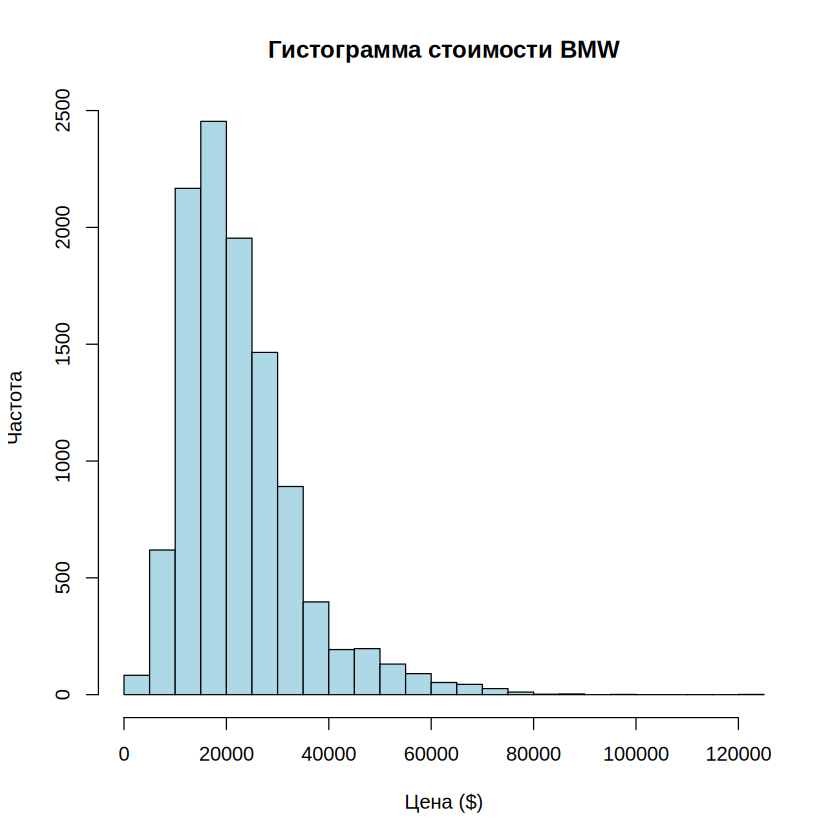

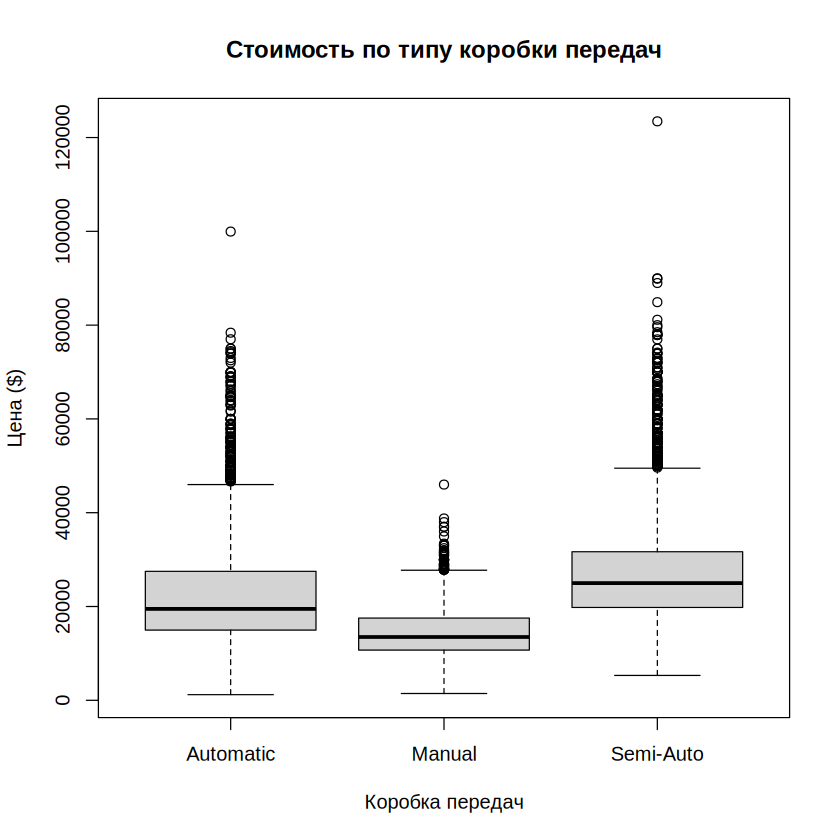

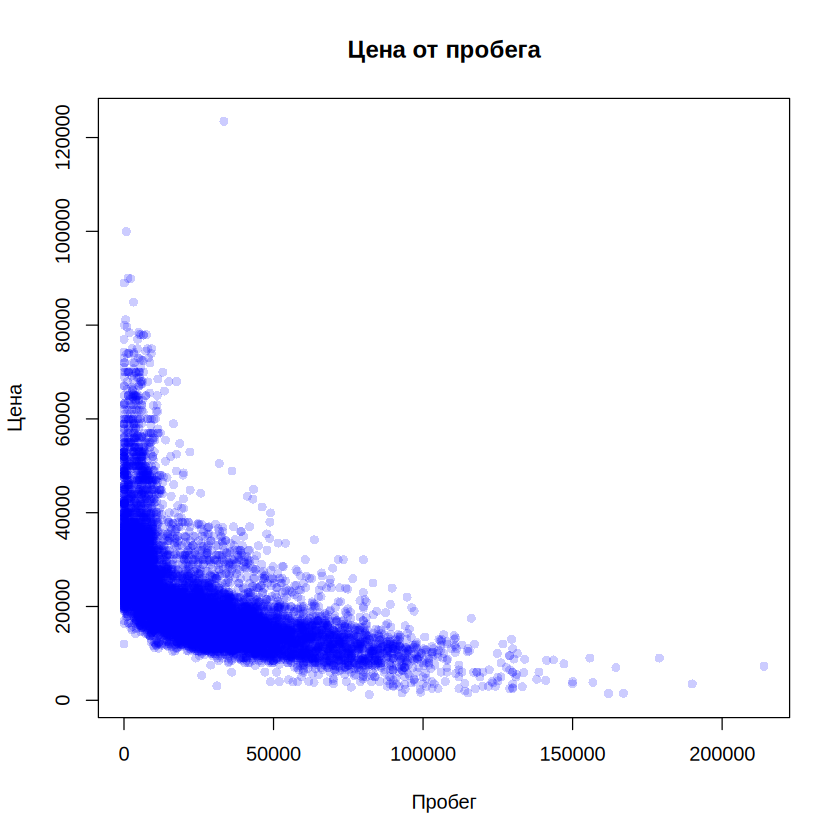

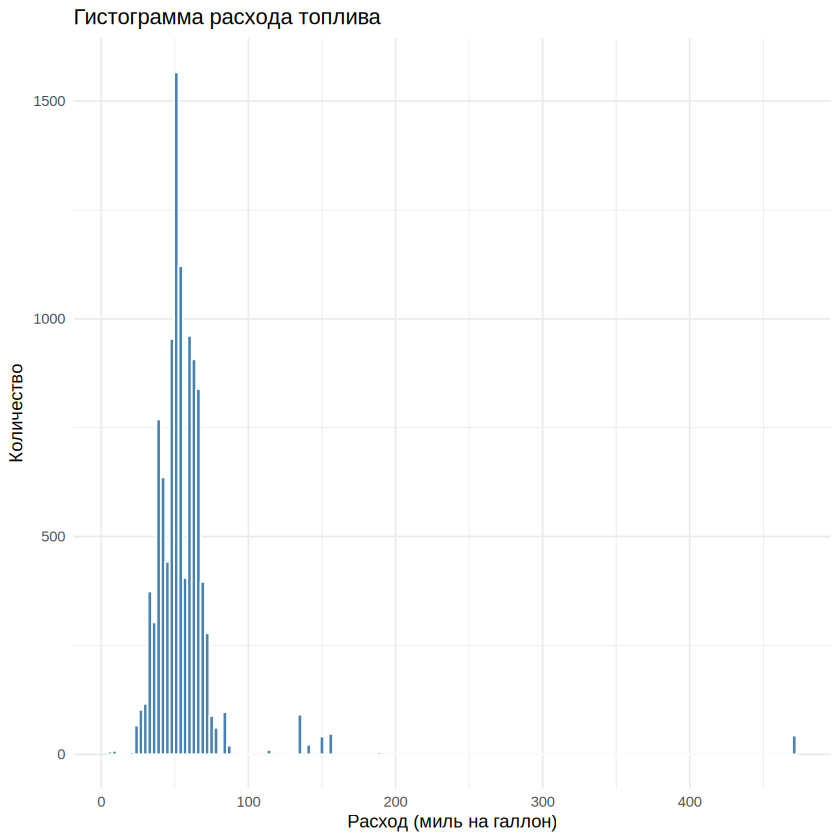

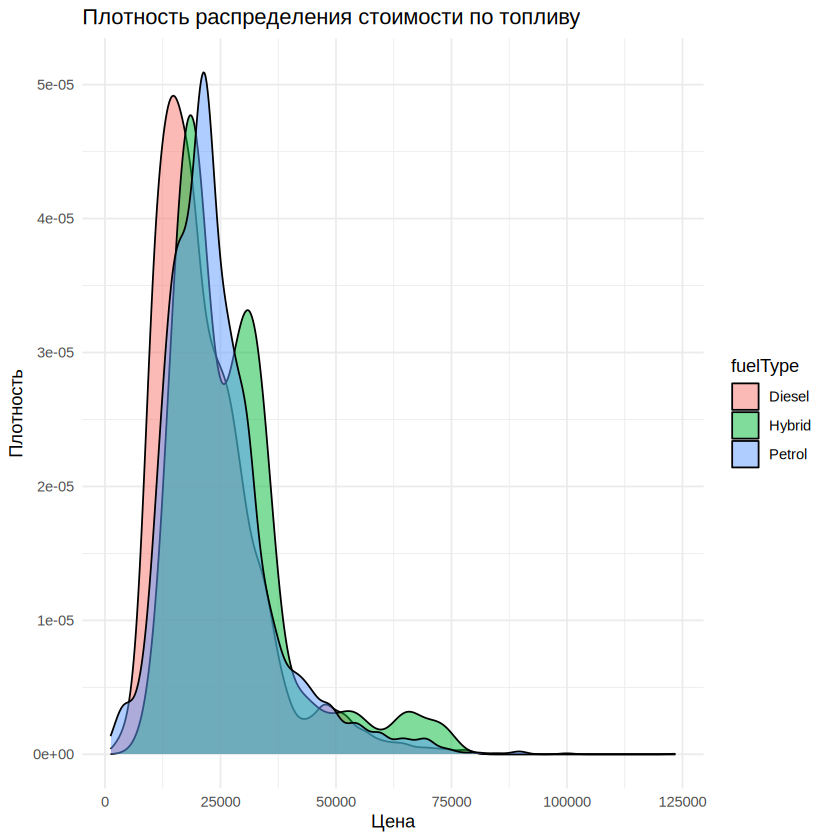

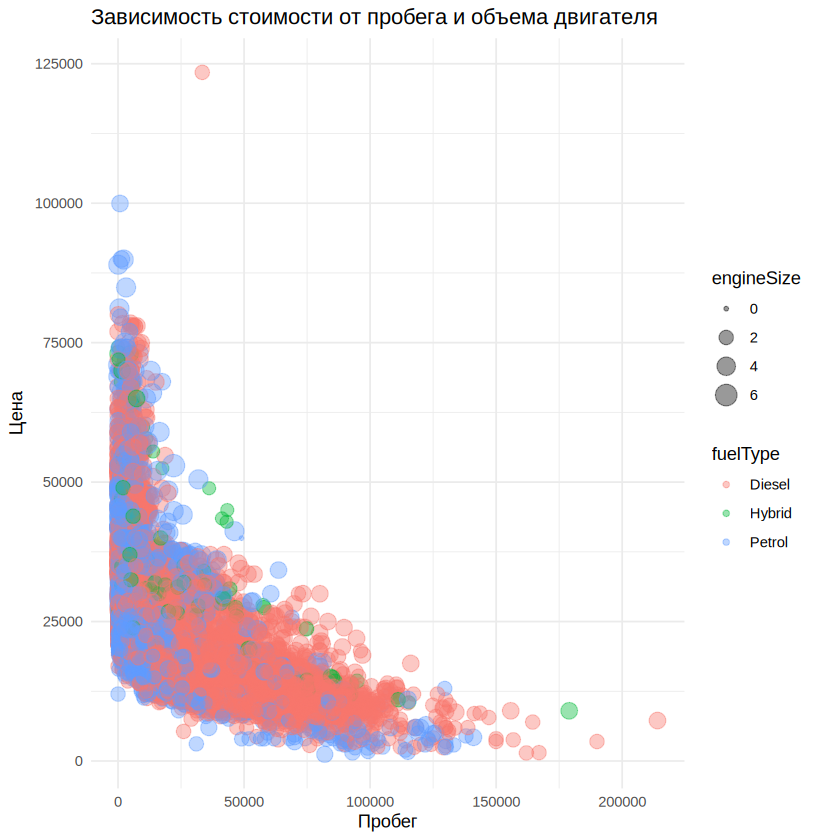

In [5]:
# Занятие 3. Описательные статистики и графики

library(psych)
library(ggplot2)

# Загружаем датасет с маркой BMW
df <- read.csv("bmw.csv", stringsAsFactors = TRUE)
str(df)

# 1. Описательные статистики для цены
mean(df$price)
median(df$price)
sd(df$price)
range(df$price)

# 2. Средняя стоимость по типу топлива
aggregate(price ~ fuelType, data = df, FUN = mean)

# 3. Средняя стоимость по типу топлива и коробке передач
aggregate(price ~ fuelType + transmission, data = df, FUN = mean)

# 4. Описательная статистика через psych::describe
describe(df)
describe(df[, c("price", "mpg")])

# 5. Стандартные графики R
# гистограмма цены
hist(df$price, breaks = 20, col = "lightblue", main = "Гистограмма стоимости BMW", xlab = "Цена ($)", ylab = "Частота")

# ящик с усами
boxplot(price ~ transmission, data = df, main = "Стоимость по типу коробки передач", xlab = "Коробка передач", ylab = "Цена ($)")

# точечная диаграмма
plot(df$mileage, df$price, pch = 16, col = rgb(0, 0, 1, 0.2), main = "Цена от пробега", xlab = "Пробег", ylab = "Цена")

# 6. Гистограмма через ggplot2 для расхода (mpg)
ggplot(df, aes(x = mpg)) +
  geom_histogram(binwidth = 3, fill = "steelblue", color = "white") +
  theme_minimal() +
  labs(title = "Гистограмма расхода топлива", x = "Расход (миль на галлон)", y = "Количество")

# 7. График плотности стоимости по типу топлива
ggplot(subset(df, fuelType %in% c("Diesel", "Petrol", "Hybrid")), aes(x = price, fill = fuelType)) +
  geom_density(alpha = 0.5) +
  theme_minimal() +
  labs(title = "Плотность распределения стоимости по топливу", x = "Цена", y = "Плотность")

# 8. Точечная диаграмма: цена от пробега, цвет - топливо, размер - объем двигателя
ggplot(subset(df, fuelType %in% c("Diesel", "Petrol", "Hybrid")),
       aes(x = mileage, y = price, color = fuelType, size = engineSize)) +
  geom_point(alpha = 0.4) +
  theme_minimal() +
  labs(title = "Зависимость стоимости от пробега и объема двигателя", x = "Пробег", y = "Цена")


## ПЗ 4. Корреляция и линейная регрессия (bmw.csv)



	Pearson's product-moment correlation

data:  df$mileage and df$price
t = -78.969, df = 10779, p-value < 2.2e-16
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 -0.6172200 -0.5933002
sample estimates:
       cor 
-0.6053968 


,year,price,mileage,tax,mpg,engineSize
year,1.00000000,0.6237561,-0.774382019,0.02519978,-0.07176235,-0.026336510
price,0.62375608,1.0000000,-0.605396767,0.26348375,-0.20488230,0.460196188
mileage,-0.77438202,-0.6053968,1.000000000,-0.17074656,0.11860869,-0.002539845
tax,0.02519978,0.2634838,-0.170746564,1.00000000,-0.35179753,0.429616336
mpg,-0.07176235,-0.2048823,0.118608693,-0.35179753,1.00000000,-0.399843528
engineSize,-0.02633651,0.4601962,-0.002539845,0.42961634,-0.39984353,1.000000000


,year,price,mileage,tax,mpg,engineSize
year,1.00000000,0.6237561,-0.774382019,0.02519978,-0.07176235,-0.026336510
price,0.62375608,1.0000000,-0.605396767,0.26348375,-0.20488230,0.460196188
mileage,-0.77438202,-0.6053968,1.000000000,-0.17074656,0.11860869,-0.002539845
tax,0.02519978,0.2634838,-0.170746564,1.00000000,-0.35179753,0.429616336
mpg,-0.07176235,-0.2048823,0.118608693,-0.35179753,1.00000000,-0.399843528
engineSize,-0.02633651,0.4601962,-0.002539845,0.42961634,-0.39984353,1.000000000


,year,price,mileage,tax,mpg,engineSize
year,0.000000e+00,0.000000e+00,0.000000e+00,1.873006e-02,3.462109e-13,0.01873006
price,0.000000e+00,0.000000e+00,0.000000e+00,9.042886e-170,1.107944e-101,0.00000000
mileage,0.000000e+00,0.000000e+00,0.000000e+00,1.499540e-70,2.217522e-34,0.79202188
tax,8.879843e-03,1.130361e-170,2.499234e-71,0.000000e+00,1.138537e-310,0.00000000
mpg,8.655272e-14,1.582776e-102,4.435045e-35,1.265042e-311,0.000000e+00,0.00000000
engineSize,6.243354e-03,0.000000e+00,7.920219e-01,0.000000e+00,0.000000e+00,0.00000000



Call:
lm(formula = price ~ mileage, data = df)

Coefficients:
(Intercept)      mileage  
 29741.5775      -0.2749  



Call:
lm(formula = price ~ mileage, data = df)

Residuals:
   Min     1Q Median     3Q    Max 
-18124  -5632  -1925   2950 102900 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  2.974e+04  1.246e+02  238.63   <2e-16 ***
mileage     -2.749e-01  3.481e-03  -78.97   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 9086 on 10779 degrees of freedom
Multiple R-squared:  0.3665,	Adjusted R-squared:  0.3664 
F-statistic:  6236 on 1 and 10779 DF,  p-value: < 2.2e-16


`geom_smooth()` using formula = 'y ~ x'


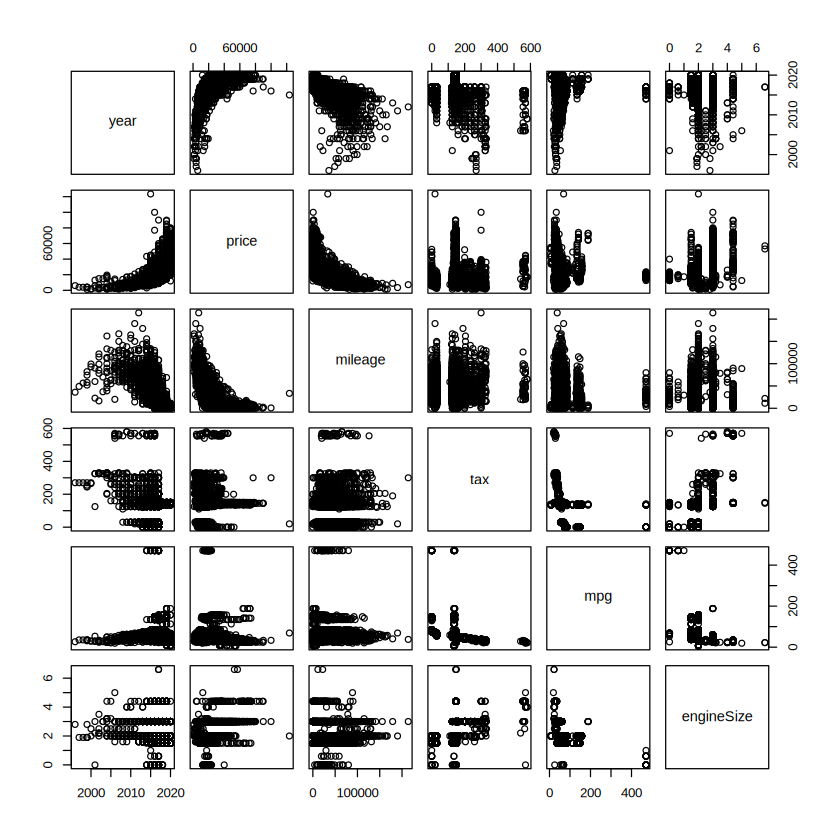

`geom_smooth()` using formula = 'y ~ x'


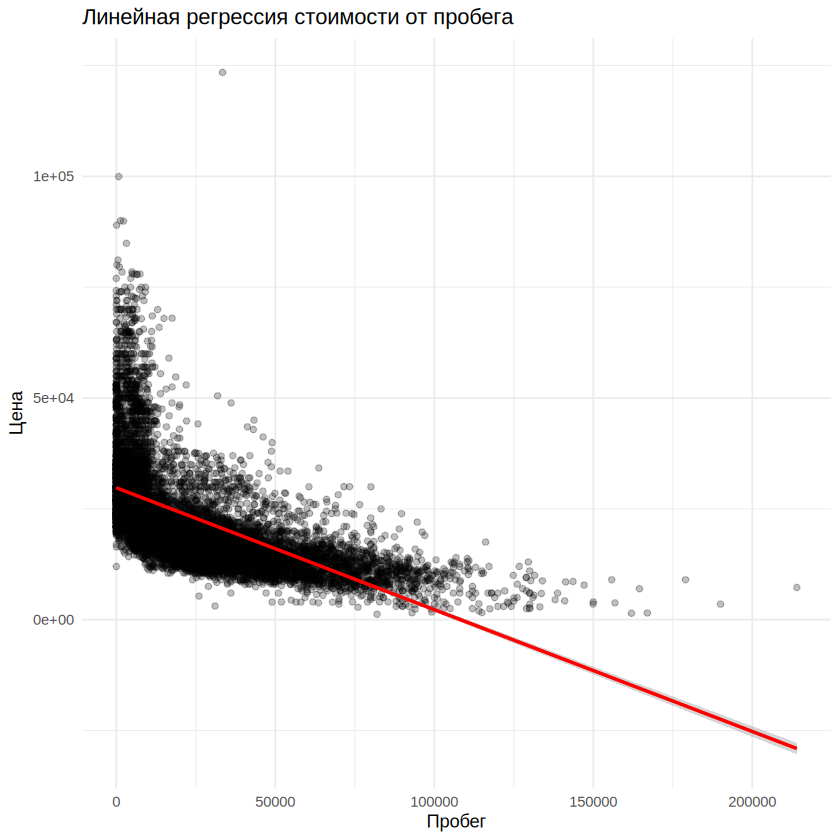

`geom_smooth()` using formula = 'y ~ x'


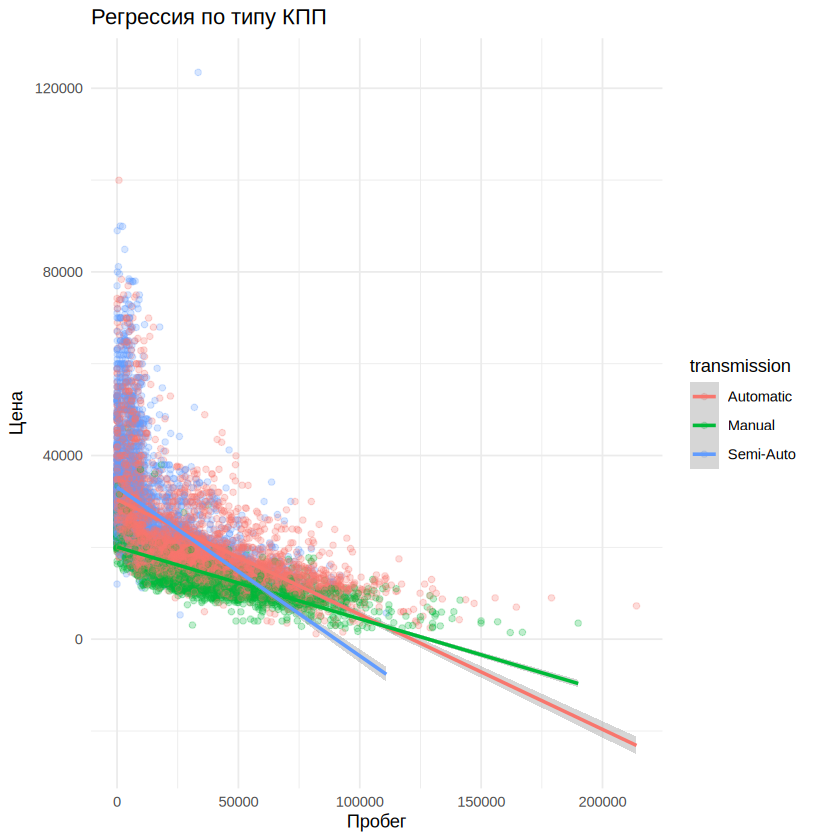

1         2         3         4         5 
 29311.69  20784.63  27038.58 -64658.62  26980.58

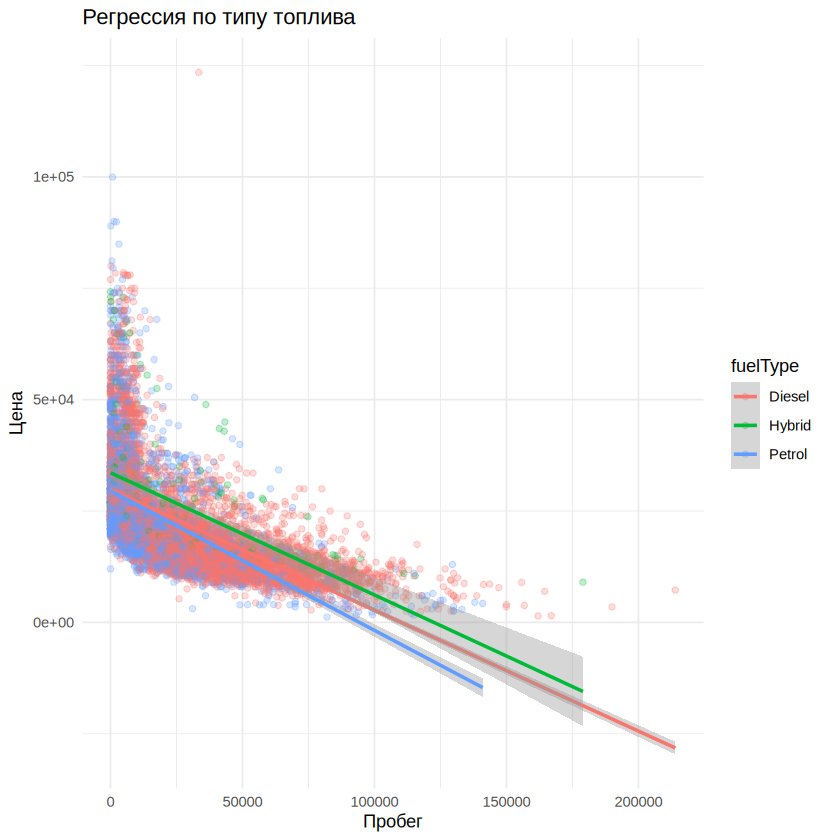

In [6]:
# Занятие 4. Корреляция и линейная регрессия

library(psych)
library(ggplot2)

df <- read.csv("bmw.csv", stringsAsFactors = TRUE)

# 1. Корреляция цены и пробега
cor.test(df$mileage, df$price)

# 2-3. Датасет только с численными переменными и парные диаграммы
df_numeric <- df[, c("year", "price", "mileage", "tax", "mpg", "engineSize")]
pairs(df_numeric)

# 4. Матрица корреляций и проверка значимости
cor(df_numeric)
fit_corr <- corr.test(df_numeric)
fit_corr$r
fit_corr$p

# 5. Парная линейная регрессия цены от пробега
fit <- lm(price ~ mileage, data = df)
fit
summary(fit)

# 6. Точечная диаграмма с линией тренда
ggplot(df, aes(x = mileage, y = price)) +
  geom_point(alpha = 0.25) +
  geom_smooth(method = "lm", col = "red") +
  theme_minimal() +
  labs(title = "Линейная регрессия стоимости от пробега", x = "Пробег", y = "Цена")

# 7. Добавление факторов (коробка передач и тип топлива)
ggplot(df, aes(x = mileage, y = price, col = transmission)) +
  geom_point(alpha = 0.25) +
  geom_smooth(method = "lm") +
  theme_minimal() +
  labs(title = "Регрессия по типу КПП", x = "Пробег", y = "Цена")

ggplot(subset(df, fuelType %in% c("Diesel", "Petrol", "Hybrid")), aes(x = mileage, y = price, col = fuelType)) +
  geom_point(alpha = 0.25) +
  geom_smooth(method = "lm") +
  theme_minimal() +
  labs(title = "Регрессия по типу топлива", x = "Пробег", y = "Цена")

# 8. Прогноз по модели
new_mileage <- data.frame(mileage = c(1564, 32587, 9834, 343445, 10045))
predict(fit, new_mileage)


## ПЗ 5. Множественная линейная регрессия (bmw.csv)


In [7]:
# Занятие 5. Множественная линейная регрессия

df <- read.csv("bmw.csv", stringsAsFactors = TRUE)

# 1. Множественная регрессия от года и пробега
fit1 <- lm(price ~ year + mileage, data = df)
fit1
summary(fit1)

# 2. Модель со всеми факторами
fit_all <- lm(price ~ ., data = df)
summary(fit_all)

# Исключаем налог и расход для проверки через ANOVA
fit_reduced <- lm(price ~ model + year + transmission + mileage + fuelType + engineSize, data = df)
anova(fit_all, fit_reduced)

# 3. Пошаговое исключение факторов
opt_model <- step(fit_all, direction = "backward")
summary(opt_model)



Call:
lm(formula = price ~ year + mileage, data = df)

Coefficients:
(Intercept)         year      mileage  
 -3.768e+06    1.881e+03   -1.388e-01  



Call:
lm(formula = price ~ year + mileage, data = df)

Residuals:
   Min     1Q Median     3Q    Max 
-19770  -5077  -1894   2254 105732 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept) -3.768e+06  1.131e+05  -33.31   <2e-16 ***
year         1.881e+03  5.603e+01   33.57   <2e-16 ***
mileage     -1.388e-01  5.234e-03  -26.51   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 8646 on 10778 degrees of freedom
Multiple R-squared:  0.4265,	Adjusted R-squared:  0.4264 
F-statistic:  4007 on 2 and 10778 DF,  p-value: < 2.2e-16



Call:
lm(formula = price ~ ., data = df)

Residuals:
   Min     1Q Median     3Q    Max 
-22098  -2260   -408   1606 110052 

Coefficients:
                        Estimate Std. Error t value Pr(>|t|)    
(Intercept)           -3.561e+06  5.936e+04 -59.986  < 2e-16 ***
model 2 Series        -1.031e+02  1.547e+02  -0.666  0.50515    
model 3 Series         2.646e+03  1.362e+02  19.427  < 2e-16 ***
model 4 Series         2.607e+03  1.714e+02  15.215  < 2e-16 ***
model 5 Series         4.596e+03  1.743e+02  26.375  < 2e-16 ***
model 6 Series         5.047e+03  4.278e+02  11.797  < 2e-16 ***
model 7 Series         1.334e+04  4.358e+02  30.621  < 2e-16 ***
model 8 Series         3.244e+04  6.909e+02  46.949  < 2e-16 ***
model i3               5.065e+04  1.760e+03  28.776  < 2e-16 ***
model i8               4.002e+04  1.050e+03  38.094  < 2e-16 ***
model M2               1.322e+04  9.234e+02  14.315  < 2e-16 ***
model M3               1.602e+04  8.290e+02  19.320  < 2e-16 ***
model M4      

,Res.Df,RSS,Df,Sum of Sq,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,10746,185993057324,NA,NA,NA,NA
2,10748,197951748233,-2,-11958690910,345.4648,3.913864e-146


Start:  AIC=179718.5
price ~ model + year + transmission + mileage + fuelType + tax + 
    mpg + engineSize

               Df  Sum of Sq        RSS    AIC
<none>                       1.8599e+11 179718
- transmission  2 2.3516e+09 1.8834e+11 179850
- tax           1 2.8372e+09 1.8883e+11 179880
- fuelType      4 1.0577e+10 1.9657e+11 180307
- mpg           1 1.1243e+10 1.9724e+11 180349
- engineSize    1 1.9009e+10 2.0500e+11 180766
- mileage       1 3.0841e+10 2.1683e+11 181371
- year          1 6.3206e+10 2.4920e+11 182870
- model        23 2.8292e+11 4.6891e+11 189642



Call:
lm(formula = price ~ model + year + transmission + mileage + 
    fuelType + tax + mpg + engineSize, data = df)

Residuals:
   Min     1Q Median     3Q    Max 
-22098  -2260   -408   1606 110052 

Coefficients:
                        Estimate Std. Error t value Pr(>|t|)    
(Intercept)           -3.561e+06  5.936e+04 -59.986  < 2e-16 ***
model 2 Series        -1.031e+02  1.547e+02  -0.666  0.50515    
model 3 Series         2.646e+03  1.362e+02  19.427  < 2e-16 ***
model 4 Series         2.607e+03  1.714e+02  15.215  < 2e-16 ***
model 5 Series         4.596e+03  1.743e+02  26.375  < 2e-16 ***
model 6 Series         5.047e+03  4.278e+02  11.797  < 2e-16 ***
model 7 Series         1.334e+04  4.358e+02  30.621  < 2e-16 ***
model 8 Series         3.244e+04  6.909e+02  46.949  < 2e-16 ***
model i3               5.065e+04  1.760e+03  28.776  < 2e-16 ***
model i8               4.002e+04  1.050e+03  38.094  < 2e-16 ***
model M2               1.322e+04  9.234e+02  14.315  < 2e-16 ***
mo

## ПЗ 6. Логистическая регрессия (Employee.csv)


'data.frame':	4653 obs. of  9 variables:
 $ Education                : Factor w/ 3 levels "Bachelors","Masters",..: 1 1 1 2 2 1 1 1 1 2 ...
 $ JoiningYear              : int  2017 2013 2014 2016 2017 2016 2015 2016 2016 2017 ...
 $ City                     : Factor w/ 3 levels "Bangalore","New Delhi",..: 1 3 2 1 3 1 2 1 3 2 ...
 $ PaymentTier              : int  3 1 3 3 3 3 3 3 3 2 ...
 $ Age                      : int  34 28 38 27 24 22 38 34 23 37 ...
 $ Gender                   : Factor w/ 2 levels "Female","Male": 2 1 1 2 2 2 2 1 2 2 ...
 $ EverBenched              : Factor w/ 2 levels "No","Yes": 1 1 1 1 2 1 1 1 1 1 ...
 $ ExperienceInCurrentDomain: int  0 3 2 5 2 0 0 2 1 2 ...
 $ LeaveOrNot               : int  0 1 0 1 1 0 0 1 0 0 ...



Call:
glm(formula = LeaveOrNot ~ Gender + Age + PaymentTier, family = "binomial", 
    data = df)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept)  2.030113   0.249774   8.128 4.37e-16 ***
GenderMale  -0.810816   0.065411 -12.396  < 2e-16 ***
Age         -0.024146   0.006762  -3.571 0.000356 ***
PaymentTier -0.565329   0.055879 -10.117  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 5989  on 4652  degrees of freedom
Residual deviance: 5648  on 4649  degrees of freedom
AIC: 5656

Number of Fisher Scoring iterations: 4


(Intercept)  GenderMale         Age PaymentTier 
  7.6149458   0.4444950   0.9761434   0.5681733

,Gender,Age,PaymentTier,LeaveOrNot,prob
,<fct>,<int>,<int>,<int>,<dbl>
1,Male,34,3,0,0.2145614
2,Female,28,1,1,0.6875527
3,Female,38,3,0,0.3581477
4,Male,27,3,1,0.2444148
5,Male,24,3,1,0.2580385
6,Male,22,3,0,0.2673916


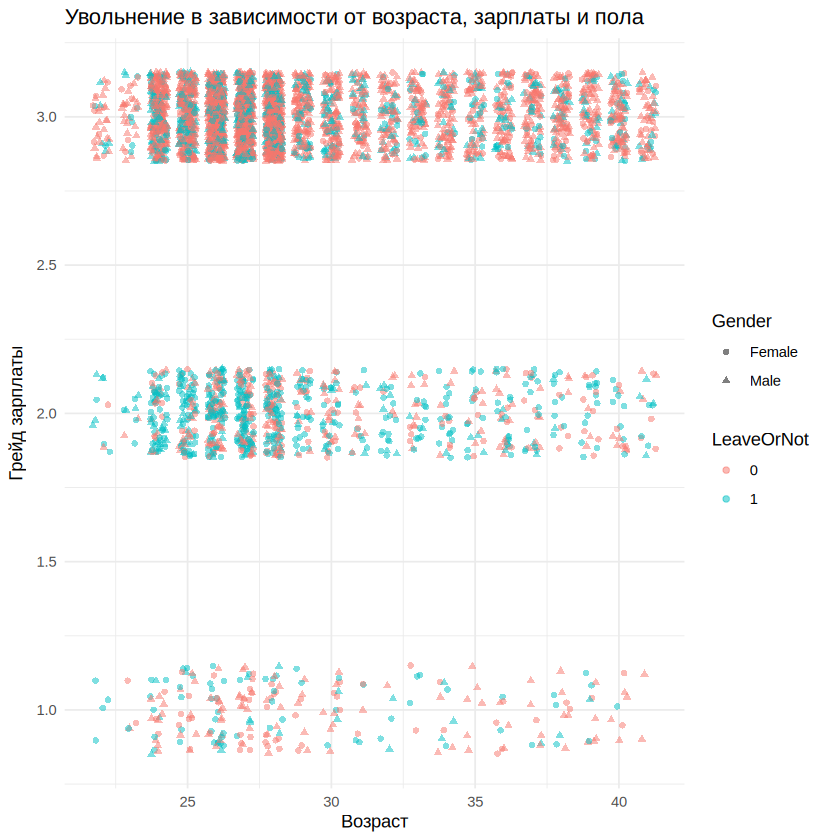

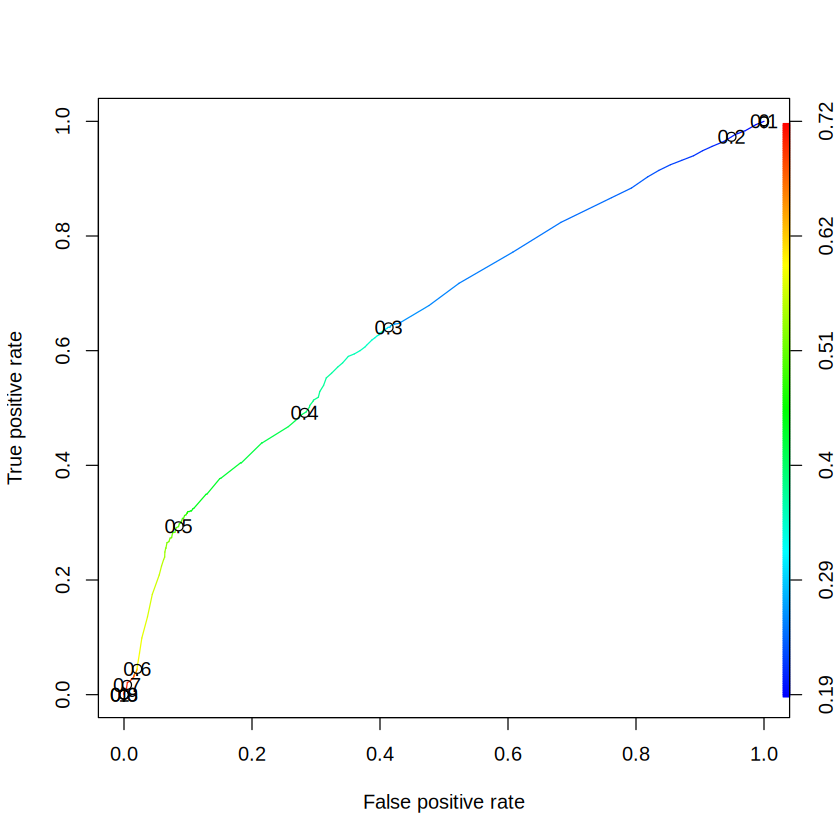

[1] 0.3471242

    Прогноз
Факт    0    1
   0 1870 1183
   1  610  990

[1] 0.6146572

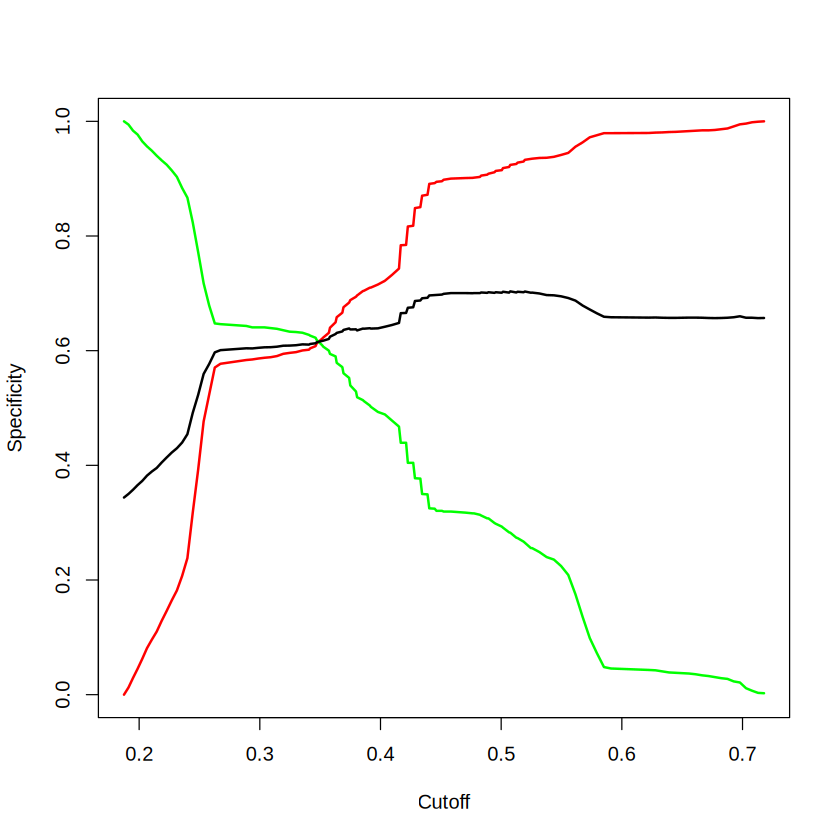

In [8]:
# Занятие 6. Логистическая регрессия

library(ggplot2)
library(ROCR)

# 1. Загрузка данных
df <- read.csv("Employee.csv", stringsAsFactors = TRUE)
str(df)

# 2. Точечная диаграмма
ggplot(df, aes(x = Age, y = PaymentTier, col = factor(LeaveOrNot), shape = Gender)) +
  geom_jitter(width = 0.3, height = 0.15, alpha = 0.5) +
  theme_minimal() +
  labs(title = "Увольнение в зависимости от возраста, зарплаты и пола",
       x = "Возраст", y = "Грейд зарплаты", col = "LeaveOrNot")

# 3. Модель логистической регрессии
fit <- glm(LeaveOrNot ~ Gender + Age + PaymentTier, data = df, family = "binomial")
summary(fit)
exp(fit$coefficients)

# 4. Предсказанные вероятности
df$prob <- predict(fit, type = "response")
head(df[, c("Gender", "Age", "PaymentTier", "LeaveOrNot", "prob")])

# 5. ROC-кривая
pred_fit <- prediction(df$prob, df$LeaveOrNot)
perf_fit <- performance(pred_fit, "tpr", "fpr")
plot(perf_fit, colorize = TRUE, print.cutoffs.at = seq(0, 1, by = 0.1))

# 6. Специфичность и чувствительность
perf_spec <- performance(pred_fit, x.measure = "cutoff", measure = "spec")
perf_sens <- performance(pred_fit, x.measure = "cutoff", measure = "sens")
perf_acc  <- performance(pred_fit, x.measure = "cutoff", measure = "acc")

plot(perf_spec, col = "red", lwd = 2)
plot(perf_sens, col = "green", lwd = 2, add = TRUE)
plot(perf_acc,  col = "black", lwd = 2, add = TRUE)

# точка пересечения чувствительности и специфичности
cutoffs <- perf_spec@x.values[[1]]
spec_vals <- perf_spec@y.values[[1]]
sens_vals <- perf_sens@y.values[[1]]
cutoff <- cutoffs[which.min(abs(spec_vals - sens_vals))]
cutoff

# 7. Классификация по выбранному порогу
df$pred_resp <- ifelse(df$prob >= cutoff, 1, 0)

# 8. Сравнение с фактом и расчет точности
df$correct <- ifelse(df$pred_resp == df$LeaveOrNot, 1, 0)
table(Факт = df$LeaveOrNot, Прогноз = df$pred_resp)
accuracy <- sum(df$correct) / nrow(df)
accuracy


## ПЗ 7. Методы машинного обучения (iris: Дерево решений, Random Forest, SVM)


Loading required package: grid

Loading required package: mvtnorm

Loading required package: modeltools

Loading required package: stats4

Loading required package: strucchange

Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric


Loading required package: sandwich

randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


Attaching package: ‘randomForest’


The following object is masked from ‘package:ggplot2’:

    margin


The following object is masked from ‘package:psych’:

    outlier



Attaching package: ‘e1071’


The following object is masked from ‘package:ggplot2’:

    element




            predict_model
             setosa versicolor virginica
  setosa         15          0         0
  versicolor      0         15         0
  virginica       0          3        12

[1] 0.9333333


Call:
 randomForest(x = train[-5], y = train$Species, ntree = 500) 
               Type of random forest: classification
                     Number of trees: 500
No. of variables tried at each split: 2

        OOB estimate of  error rate: 4.76%
Confusion matrix:
           setosa versicolor virginica class.error
setosa         35          0         0  0.00000000
versicolor      0         32         3  0.08571429
virginica       0          2        33  0.05714286

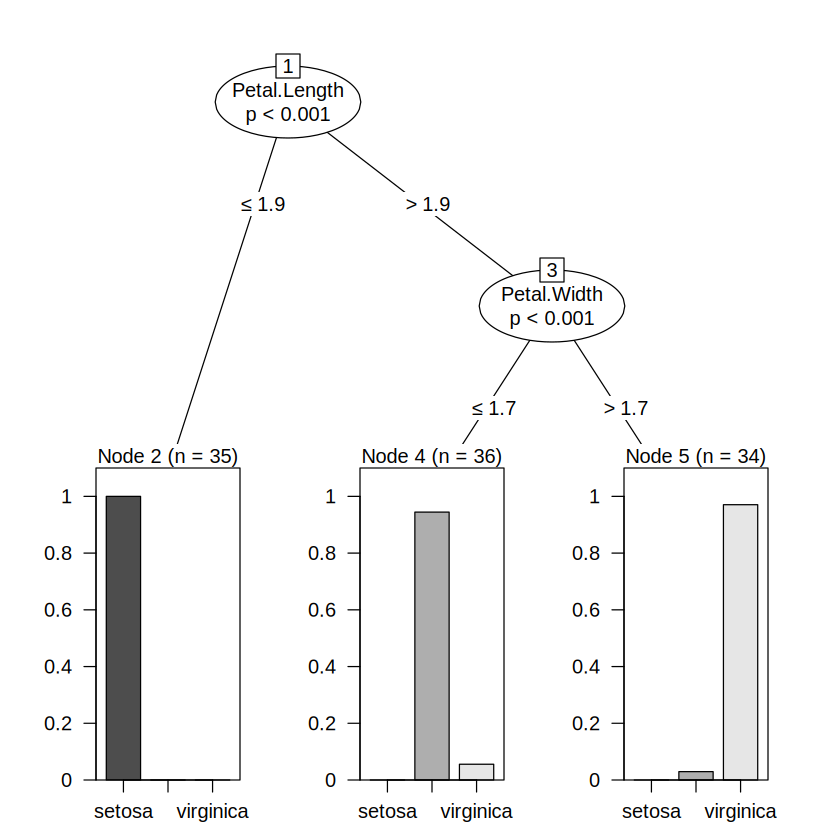

,MeanDecreaseGini
Sepal.Length,7.097560
Sepal.Width,1.261665
Petal.Length,27.848674
Petal.Width,33.066996


            y_pred
             setosa versicolor virginica
  setosa         15          0         0
  versicolor      0         15         0
  virginica       0          4        11

[1] 0.9111111


Call:
svm(formula = Species ~ ., data = train, type = "C-classification", 
    kernel = "linear")


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  linear 
       cost:  1 

Number of Support Vectors:  22


            y_pred3
             setosa versicolor virginica
  setosa         15          0         0
  versicolor      0         15         0
  virginica       0          1        14

[1] 0.9777778

Model,Accuracy
<chr>,<dbl>
Дерево решений,0.9333333
Случайный лес,0.9111111
SVM,0.9777778


,Model,Accuracy
,<chr>,<dbl>
3,SVM,0.9777778


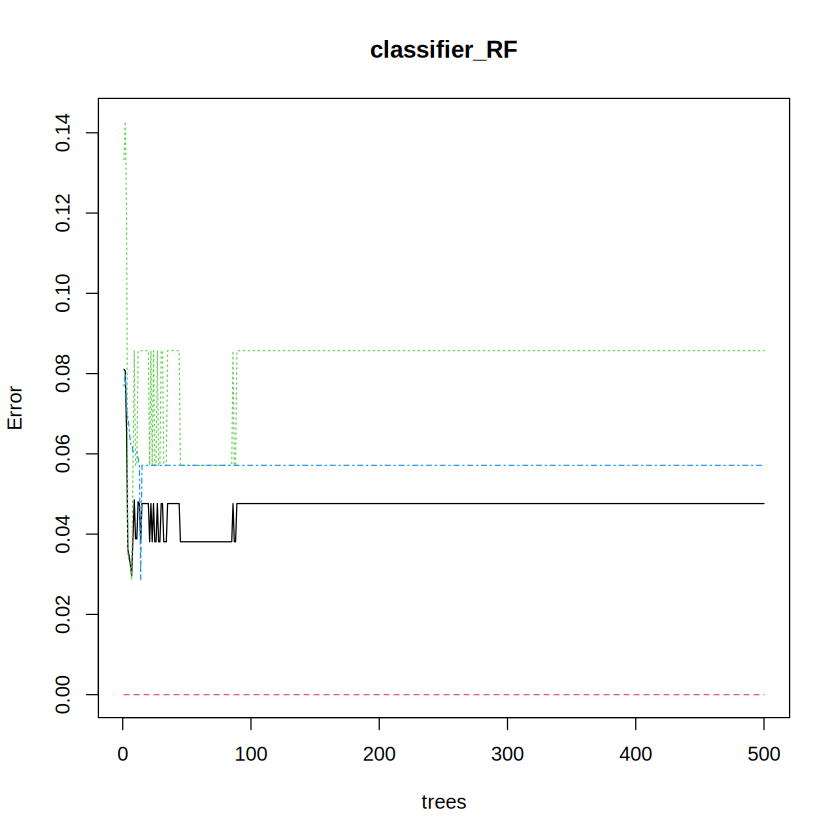

In [9]:
# Занятие 7. Методы машинного обучения

library(caTools)
library(party)
library(randomForest)
library(e1071)

# 1. Загрузка данных iris и разбивка 70/30
df <- iris

set.seed(42)
sample <- sample.split(df$Species, SplitRatio = 0.7)
train <- subset(df, sample == TRUE)
test  <- subset(df, sample == FALSE)

# 2.1 Дерево решений
model <- ctree(Species ~ ., train)
plot(model)

predict_model <- predict(model, test)
m_at <- table(test$Species, predict_model)
m_at
ac_Test <- sum(diag(m_at)) / sum(m_at)
ac_Test

# 2.2 Случайный лес
classifier_RF <- randomForest(x = train[-5], y = train$Species, ntree = 500)
classifier_RF
plot(classifier_RF)

importance(classifier_RF)

y_pred <- predict(classifier_RF, newdata = test[-5])
confusion_mtx <- table(test[, 5], y_pred)
confusion_mtx
ac_Test2 <- sum(diag(confusion_mtx)) / sum(confusion_mtx)
ac_Test2

# 2.3 Метод опорных векторов (SVM)
classifier <- svm(formula = Species ~ ., data = train, type = "C-classification", kernel = "linear")
classifier

y_pred3 <- predict(classifier, newdata = test[-5])
cm <- table(test[, 5], y_pred3)
cm
ac_Test3 <- sum(diag(cm)) / sum(cm)
ac_Test3

# 3. Итоговая таблица точности
results <- data.frame(
  Model = c("Дерево решений", "Случайный лес", "SVM"),
  Accuracy = c(ac_Test, ac_Test2, ac_Test3)
)
results

# 4. Наиболее точный метод
results[which.max(results$Accuracy), ]
